#Dataset Dados Abertos STJ - Íntegras de Decisões Terminativas e Acórdãos do Diário da Justiça (Decisões)

##Experimento 15: Habeas Corpus only,  Mean Pooling, BerTimbau.

##Importação de bibliotecas e declaração de variáveis globais

In [1]:
ENVIRONMENT = 'COLAB' #'PUCPR'

import torch

# Check if a GPU (CUDA) is available
if torch.cuda.is_available():
    print("GPU is available!")
    print("Device Name:", torch.cuda.get_device_name(0))
else:
    print("GPU not available, using CPU.")

# This is the line you'd use in your script to send your model or data to the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

GPU is available!
Device Name: NVIDIA L4
Using device: cuda


##Parametrização conforme ambiente de execução.

In [2]:
import pandas as pd

# Define the base path to the dataset folder
if ENVIRONMENT == 'COLAB':
  from google.colab import drive
  drive.mount('/content/drive')

  base_path = '/content/drive/MyDrive/_Mestrado PUCPR/Datasets/'
  num_layers_to_freeze = 6 # You can adjust this number based on your inspection of layer names
  #model_checkpoint = 'neuralmind/bert-base-portuguese-cased'
  model_checkpoint = 'neuralmind/bert-large-portuguese-cased'
  EPOCHS = 12
  APPROACH_EXECUTION = 'step'
  reduced_embedding_dim = 512
  per_device_train_batch_size = 8
  per_device_eval_batch_size = 8
  # Define output directory
  output_dir = './results'
  install_evaluate = False
elif ENVIRONMENT == 'PUCPR':
  num_layers_to_freeze = 6 # Result get after trade-offs layers freezing BigBird (Trade-off freezing layers in BigBird.ipynb)
  base_path = 'dataset/'
  model_checkpoint = 'neuralmind/bert-large-portuguese-cased'
  EPOCHS = 75
  APPROACH_EXECUTION = 'epoch'
  reduced_embedding_dim = 512
  per_device_train_batch_size = 16
  per_device_eval_batch_size = 16

  # Define output directory
  output_dir = '/dados_abertos_stj/saved_models/hc-bertimbau'

  # Before execution, check install packages

  # !pip install tiktoken
  # !pip install sentencepiece
  # !pip install evaluate
  install_evaluate = True
else:
  raise Exception("Environment of execution is not recognize!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##Carregar classe/rótulo para a decisão (Favorável ou Não ao Réu)

In [3]:
# Define file paths
file_path = base_path + 'descricao-decisao-julgamento.csv'

# Load each CSV file into a dataframe
try:
    dfTipoDecisao = pd.read_csv(file_path, sep=';')
    print(f"Successfully loaded {file_path} into dataframe 'dfTipoDecisao'")
    display(dfTipoDecisao.head())
except FileNotFoundError:
    print(f"Error: File not found at {file_path}")
except Exception as e:
    print(f"An error occurred while loading {file_path}: {e}")

Successfully loaded /content/drive/MyDrive/_Mestrado PUCPR/Datasets/descricao-decisao-julgamento.csv into dataframe 'dfTipoDecisao'


,COD_TEOR_DECISAO,DESC_TEOR_DECISAO,DESC_RSULT_JGTO,RESULTADO_RESUMIDO,DECISAO_FAVORAVEL
0,1,Concedendo,"AGRAVO CONHECIDO EM PARTE E, NESSA PARTE, PROVIDO",PARCIALMENTE CONHECIDO E PROVIDO,S
1,1,Concedendo,Agravo regimental provido,PROVIDO,S
2,1,Concedendo,CONCEDENDO HABEAS CORPUS,CONCEDIDO,S
3,1,Concedendo,CONCEDENDO HABEAS DATA,CONCEDIDO,S
4,1,Concedendo,CONCEDENDO MANDADO DE SEGURANÇA,CONCEDIDA,S


##Carregar metadados das decisões (Documento, Processo, Nro de Registro, Ministro, Teor).

In [4]:
file_path = base_path + 'metadados-decisoes-acordaos-dj052025.csv'

try:
    dfMetaDadosDecisao = pd.read_csv(file_path, sep=';')
    print(f"Successfully loaded {file_path} into dataframe 'dfMetaDadosDecisao'")
    display(dfMetaDadosDecisao.head(3))
except FileNotFoundError:
    print(f"Error: File not found at {file_path}")
except Exception as e:
    print(f"An error occurred while loading {file_path}: {e}")

Successfully loaded /content/drive/MyDrive/_Mestrado PUCPR/Datasets/metadados-decisoes-acordaos-dj052025.csv into dataframe 'dfMetaDadosDecisao'


,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,PROCESSO,DATARECEBIMENTO,DATADISTRIBUICAO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,ASSUNTOS
0,309631639,2025-05-05,DECISÃO,202000946481,TP 2695,2020-04-25,2020-04-27,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...,4993
1,310378377,2025-05-05,DECISÃO,202400362531,AREsp 2562174,2024-02-09,2024-02-28,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...,"11806, 7752, 7780, 7779"
2,309409286,2025-05-05,DECISÃO,202401080738,REsp 2132967,2024-04-02,2024-04-04,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...,"3416, 3435"


##Carregar detalhes das decisões

In [5]:
# Define file paths
file_path = base_path + 'decisoes-acordaos-dj052025.csv'

try:
    dfDetalheDecisao = pd.read_csv(file_path, sep=';')
    print(f"Successfully loaded {file_path} into dataframe 'dfDetalheDecisao'")
    display(dfDetalheDecisao.head(3))
except FileNotFoundError:
    print(f"Error: File not found at {file_path}")
except Exception as e:
    print(f"An error occurred while loading {file_path}: {e}")

Successfully loaded /content/drive/MyDrive/_Mestrado PUCPR/Datasets/decisoes-acordaos-dj052025.csv into dataframe 'dfDetalheDecisao'


,SEQDOCUMENTO,ACORDAO,EMENTA,RELATORIO,VOTO,DECISAO
0,309631639,NaN,NaN,NaN,NaN,O presente pedido de contracautela tinha por o...
1,310378377,NaN,NaN,NaN,NaN,Trata-se de agravo em recurso especial interpo...
2,309409286,NaN,NaN,NaN,NaN,Trata-se de recurso especial interposto por MA...


##Tratamento dos dados
###Exclusão de campos desnecessários

In [6]:
dfMetaDadosDecisao.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48588 entries, 0 to 48587
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   SEQDOCUMENTO          48588 non-null  int64 
 1   DATAPUBLICACAO        48588 non-null  object
 2   TIPODOCUMENTO         48588 non-null  object
 3   NUMEROREGISTRO        48588 non-null  int64 
 4   PROCESSO              48588 non-null  object
 5   DATARECEBIMENTO       48588 non-null  object
 6   DATADISTRIBUICAO      48588 non-null  object
 7   NM_MINISTRO           48588 non-null  object
 8   RECURSO               6200 non-null   object
 9   TEOR                  48588 non-null  object
 10  DESCRICAOMONOCRATICA  48588 non-null  object
 11  ASSUNTOS              48588 non-null  object
dtypes: int64(2), object(10)
memory usage: 4.4+ MB


In [7]:
dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,DATAPUBLICACAO,TIPODOCUMENTO,NUMEROREGISTRO,PROCESSO,DATARECEBIMENTO,DATADISTRIBUICAO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,ASSUNTOS
0,309631639,2025-05-05,DECISÃO,202000946481,TP 2695,2020-04-25,2020-04-27,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...,4993
1,310378377,2025-05-05,DECISÃO,202400362531,AREsp 2562174,2024-02-09,2024-02-28,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...,"11806, 7752, 7780, 7779"
2,309409286,2025-05-05,DECISÃO,202401080738,REsp 2132967,2024-04-02,2024-04-04,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...,"3416, 3435"


In [8]:
dfMetaDadosDecisao.drop(columns=['DATAPUBLICACAO','TIPODOCUMENTO','DATARECEBIMENTO','DATADISTRIBUICAO','ASSUNTOS'], inplace=True)
dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,NUMEROREGISTRO,PROCESSO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA
0,309631639,202000946481,TP 2695,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...
1,310378377,202400362531,AREsp 2562174,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...
2,309409286,202401080738,REsp 2132967,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...


In [9]:
dfDetalheDecisao.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48027 entries, 0 to 48026
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SEQDOCUMENTO  48027 non-null  int64  
 1   ACORDAO       0 non-null      float64
 2   EMENTA        13 non-null     object 
 3   RELATORIO     0 non-null      float64
 4   VOTO          0 non-null      float64
 5   DECISAO       48011 non-null  object 
dtypes: float64(3), int64(1), object(2)
memory usage: 2.2+ MB


In [10]:
dfDetalheDecisao.head(3)

,SEQDOCUMENTO,ACORDAO,EMENTA,RELATORIO,VOTO,DECISAO
0,309631639,NaN,NaN,NaN,NaN,O presente pedido de contracautela tinha por o...
1,310378377,NaN,NaN,NaN,NaN,Trata-se de agravo em recurso especial interpo...
2,309409286,NaN,NaN,NaN,NaN,Trata-se de recurso especial interposto por MA...


In [11]:
dfDetalheDecisao.drop(columns=['ACORDAO', 'EMENTA', 'RELATORIO', 'VOTO'], inplace=True)
dfDetalheDecisao.head(3)

,SEQDOCUMENTO,DECISAO
0,309631639,O presente pedido de contracautela tinha por o...
1,310378377,Trata-se de agravo em recurso especial interpo...
2,309409286,Trata-se de recurso especial interposto por MA...


##Redução dos registros com o intuito de reduzir o tempo no treinamento e verificar a curva de convergência

###Separar o número de processo pelo tipo (Aresp, HC).

In [12]:
#field = "AREsp 2562174".split(" ")
#print(f"Tipo: '{field[0]}' Processo: '{field[1]}'  ")

dfMetaDadosDecisao['TIPOPROCESSO'] = dfMetaDadosDecisao['PROCESSO'].apply(lambda tipoprocesso: tipoprocesso.split(" ")[0])
dfMetaDadosDecisao['NUMEROPROCESSO'] = dfMetaDadosDecisao['PROCESSO'].apply(lambda numeroprocesso: numeroprocesso.split(" ")[1])
dfMetaDadosDecisao.drop(columns=['PROCESSO'], inplace=True, axis=1)

dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO
0,309631639,202000946481,MARIA ISABEL GALLOTTI,NaN,Negando,Prejudicada a ação de #{nome_da_parte} #{campo...,TP,2695
1,310378377,202400362531,JOÃO OTÁVIO DE NORONHA,NaN,Negando,Conhecido o recurso de #{nome_da_parte} e não-...,AREsp,2562174
2,309409286,202401080738,MESSOD AZULAY NETO,NaN,Concedendo,Conhecido o recurso de #{nome_da_parte} e prov...,REsp,2132967


In [13]:
dfMetaDadosDecisao['TIPOPROCESSO'].value_counts()

,count
TIPOPROCESSO,
AREsp,27718
HC,9123
REsp,6650
CC,1956
RHC,1534
RMS,349
EAREsp,309
Rcl,235
EREsp,122


###Filtrar pelo tipo de processo (HC, Resp)

In [14]:
dfMetaDadosDecisao = dfMetaDadosDecisao[dfMetaDadosDecisao['TIPOPROCESSO'] == 'HC']
dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936
6,307894140,202500147196,ROGERIO SCHIETTI CRUZ,NaN,Concedendo,Concedido o Habeas Corpus a #{nome_da_parte} #...,HC,975986
31,310138969,202501402824,HERMAN BENJAMIN,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,998137


##Preprocessing

###Noise removal

In [15]:
import re

def remove_noise(text):
    if isinstance(text, str):
        clean = re.compile('<.*?>')
        return re.sub(clean, ' ', text)
    return text

In [16]:
#Exemplo de uso da função
texto = """  <br><hr> Trata-se , de   habeas   corpus substitutivo   <b> de </b>
recurso          próprio , com pedido de liminar.Porém, tudo de bom.De bom.1.1253,00</br> """
texto = remove_noise(texto)

print(texto)

     Trata-se , de   habeas   corpus substitutivo     de  
recurso          próprio , com pedido de liminar.Porém, tudo de bom.De bom.1.1253,00  


In [17]:
import re

def _consolidate_known_acronyms(text):
    # Consolidate 'art . ' into 'art.'
    text = re.sub(r'(?i)(\bart)\s+\.', r'\1.', text)

    # Consolidate 'n . ' into 'n.'
    text = re.sub(r'(?i)(\bn)\s+\.', r'\1.', text)

    # Consolidate 'c . c .' into 'c.c.'
    text = re.sub(r'(?i)(c)\s+\.\s*(c)\s+\.', r'\1.\2.', text)

    # Consolidate 'c . c' into 'c.c'
    text = re.sub(r'(?i)(c)\s+\.\s*(c)', r'\1.\2', text)

    # Consolidate 'c. c' into 'c.c'
    # This is for when the first dot is already correctly placed, but there's a space before the second 'c'
    text = re.sub(r'(?i)(c\.)\s+(c)', r'\1\2', text)

    return text

In [18]:
text = "583 dias-multa , incurso art. 33 , caput , c. c 40 , VI , Lei n . 11.343/2006.Em sede recursal , Tribunal origem negou provimento apelo defensivo"
text = _consolidate_known_acronyms(text)
print(text)

583 dias-multa , incurso art. 33 , caput , c.c 40 , VI , Lei n. 11.343/2006.Em sede recursal , Tribunal origem negou provimento apelo defensivo


###Stopword removal


In [19]:
import re

def remove_whitespace(text):
    if not isinstance(text, str):
        return text

    # 1. Replace multiple whitespace characters with a single space and strip leading/trailing spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # 2. Consolidate specific acronym patterns (e.g., 'art . ' -> 'art.')
    #text = _consolidate_known_acronyms(text)

    # 3. Remove space before commas (e.g., 'word , ' -> 'word,')
    text = re.sub(r'\s+,', ',', text)

    # 4. Handle dot spacing with a placeholder strategy for robustness:

    # Define unique placeholders for protected dots.
    PLACEHOLDER_ACRONYM_DOT_ART = "_#_ART_DOT_#_"
    PLACEHOLDER_ACRONYM_DOT_CC = "_#_CC_DOT_#_"
    PLACEHOLDER_ACRONYM_DOT_N = "_#_N_DOT_#_"
    PLACEHOLDER_DIGIT_DOT = "_#_DIGIT_DOT_#_"

    # --- Step 4.1: Protect dots that should NOT have a space after them ---
    # Order matters here: specific patterns first.

    # Protect dots preceded by digits AND followed by digits (e.g., 1.23)
    text = re.sub(r'(\d)\.(\d)', r'\1' + PLACEHOLDER_DIGIT_DOT + r'\2', text)

    # Protect 'art.' regardless of what follows (case-insensitive).
    text = re.sub(r'(?i)(\bart)\.', r'\1' + PLACEHOLDER_ACRONYM_DOT_ART, text)
    # Protect 'c.c.' regardless of what follows (case-insensitive).
    text = re.sub(r'(?i)(\bc\.c)\.', r'\1' + PLACEHOLDER_ACRONYM_DOT_CC, text)
    # Protect 'n.' regardless of what follows (case-insensitive).
    text = re.sub(r'(?i)(\bn)\.', r'\1' + PLACEHOLDER_ACRONYM_DOT_N, text)

    # --- Step 4.2: Apply general rule to add space after *remaining* dots ---
    # This will only affect dots that were not protected by the placeholders above.
    # It adds a space if a dot is followed by a non-space character.
    text = re.sub(r'\.(?=\S)', '. ', text)

    # --- Step 4.3: Restore protected dots ---
    # Replace placeholders back to original dots.
    text = text.replace(PLACEHOLDER_ACRONYM_DOT_ART, '.')
    text = text.replace(PLACEHOLDER_ACRONYM_DOT_CC, '.')
    text = text.replace(PLACEHOLDER_ACRONYM_DOT_N, '.')
    text = text.replace(PLACEHOLDER_DIGIT_DOT, '.')

    return text

In [20]:
text = "<br>583 dias-multa , incurso art . 33 , <b>caput , </b>c. c 40 , VI , Lei n . 11.343/2006.Em sede recursal , Tribunal origem negou provimento apelo defensivo."

text = remove_noise(text)
print(f"After remove_noise: {text}")

text = remove_whitespace(text)
print(f"After remove_whitespace: {text}")

text = _consolidate_known_acronyms(text)
print(f"After remove_whitespace: {text}")


After remove_noise:  583 dias-multa , incurso art . 33 ,  caput ,  c. c 40 , VI , Lei n . 11.343/2006.Em sede recursal , Tribunal origem negou provimento apelo defensivo.
After remove_whitespace: 583 dias-multa, incurso art . 33, caput, c. c 40, VI, Lei n . 11.343/2006. Em sede recursal, Tribunal origem negou provimento apelo defensivo.
After remove_whitespace: 583 dias-multa, incurso art. 33, caput, c.c 40, VI, Lei n. 11.343/2006. Em sede recursal, Tribunal origem negou provimento apelo defensivo.


In [21]:
import nltk

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

stopwords = nltk.corpus.stopwords.words('portuguese')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [22]:
import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

def pre_processamento(texto):
    # Ensure texto is a string before processing
    if not isinstance(texto, str):
        return ""

    # Step 1: Remove HTML/XML tags (noise)
    texto = remove_noise(texto)

    # Step 2: Tokenize the text, keeping punctuation as separate tokens
    tokens = word_tokenize(texto, language='portuguese')

    # Step 3: Get Portuguese stopwords
    stop_words = set(stopwords.words('portuguese'))

    # Step 4: Filter out stopwords, keeping punctuation tokens and non-alphabetic words
    # A token is kept if it's not a stopword (when lowercased) OR if it's not purely alphabetic (e.g., punctuation, numbers)
    filtered_tokens = [w for w in tokens if w.lower() not in stop_words or not w.isalpha()]

    # Step 5: Join the tokens back into a string
    texto = " ".join(filtered_tokens)

    # Step 6: Clean whitespace, consolidate acronyms, handle comma/dot spacing
    # The remove_whitespace function now internally calls the global _consolidate_known_acronyms.
    texto = remove_whitespace(texto)

    texto = _consolidate_known_acronyms(texto)

    return texto


In [23]:
#Exemplo de uso da função
texto = """<br>Trata-se de habeas corpus <b>substitutivo de recurso próprio</b>, com pedido de liminar, impetrado em favor de LUIS FELIPE SILVA DE ASSIS, em que se aponta com autoridade coatora o Tribunal de Justiça do Estado do Rio de Janeiro.Consta dos autos que o paciente foi condenado à pena de 5 anos e 10 meses de reclusão, em regime semiaberto, mais pagamento de 583 dias-multa, como incurso no art. 33,caput, c.c o 40, VI, da Lei n. 11.343/2006.Em sede recursal, o Tribunal de origem negou provimento ao apelo defensivo."""
texto = pre_processamento(texto)

print(texto)

Trata-se habeas corpus substitutivo recurso próprio, pedido liminar, impetrado favor LUIS FELIPE SILVA ASSIS, aponta autoridade coatora Tribunal Justiça Estado Rio Janeiro. Consta autos paciente condenado pena 5 anos 10 meses reclusão, regime semiaberto, pagamento 583 dias-multa, incurso art. 33, caput, c.c 40, VI, Lei n. 11.343/2006. Em sede recursal, Tribunal origem negou provimento apelo defensivo .


In [24]:
dfDetalheDecisao['DECISAO'] = dfDetalheDecisao['DECISAO'].apply(pre_processamento)

###Junção dos Datasets em um único dataset

In [25]:
def get_decisao(seq_documento):
    # Filter dfDetalheAcordaos for the given SEQDOCUMENTO
    decisao_row = dfDetalheDecisao[dfDetalheDecisao['SEQDOCUMENTO'] == seq_documento]

    # Check if the filtered DataFrame is empty
    if not decisao_row.empty:
        # If not empty, return the 'ACORDAO' value
        return decisao_row.head(1)['DECISAO'].iloc[0]
    else:
        # If empty, return None
        return None

def get_tipo_decisao(teor_decisao):
    # Filter dfDetalheAcordaos for the given SEQDOCUMENTO
    tipo_decisao_row = dfTipoDecisao[dfTipoDecisao['DESC_TEOR_DECISAO'] == teor_decisao].head(1)

    # Check if the filtered DataFrame is empty
    if not tipo_decisao_row.empty:
        # If not empty, return the 'ACORDAO' value
        return tipo_decisao_row.head(1)['DECISAO_FAVORAVEL'].iloc[0]
    else:
        # If empty, return None
        return None

In [26]:
dfMetaDadosDecisao['DECISAO']  = dfMetaDadosDecisao['SEQDOCUMENTO'].apply(get_decisao)
dfMetaDadosDecisao['DECISAO_FAVORAVEL']  = dfMetaDadosDecisao['TEOR'].apply(get_tipo_decisao)

In [27]:
dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936,JOSIMAR TEOTONIO PONTES alega vítima coação il...,N
6,307894140,202500147196,ROGERIO SCHIETTI CRUZ,NaN,Concedendo,Concedido o Habeas Corpus a #{nome_da_parte} #...,HC,975986,GILMAR PEREIRA alega vítima coação ilegal deco...,S
31,310138969,202501402824,HERMAN BENJAMIN,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,998137,Cuida-se Habeas Corpus impetrado favor EVANDRA...,N


In [28]:
# Filter rows where 'TEOR' is not empty (NaN) and assign to a new dataframe
dfMetaDadosDecisao_filtered = dfMetaDadosDecisao.dropna(subset=['TEOR']).copy()

# Filter rows where 'DECISAO' is not empty (NaN) and assign to a new dataframe
dfMetaDadosDecisao_filtered = dfMetaDadosDecisao_filtered.dropna(subset=['DECISAO']).copy()

# Filter rows where 'DECISAO_FAVORAVEL is not empty (NaN) and assign to a new dataframe -- decisões neutras não possuem efeito jurídico considerável
dfMetaDadosDecisao_filtered = dfMetaDadosDecisao_filtered.dropna(subset=['DECISAO_FAVORAVEL']).copy()

dfMetaDadosDecisao = dfMetaDadosDecisao_filtered
dfMetaDadosDecisao.head(5)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936,JOSIMAR TEOTONIO PONTES alega vítima coação il...,N
6,307894140,202500147196,ROGERIO SCHIETTI CRUZ,NaN,Concedendo,Concedido o Habeas Corpus a #{nome_da_parte} #...,HC,975986,GILMAR PEREIRA alega vítima coação ilegal deco...,S
31,310138969,202501402824,HERMAN BENJAMIN,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,998137,Cuida-se Habeas Corpus impetrado favor EVANDRA...,N
32,310349028,202501463293,JOEL ILAN PACIORNIK,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,999017,"Cuida-se habeas corpus, pedido liminar, impetr...",N
37,309697646,202500707575,REYNALDO SOARES DA FONSECA,AgRg,Não Conhecendo,Não conhecido o Habeas Corpus de #{nome_da_par...,HC,985649,Trata-se agravo regimental interposto Ministér...,N


In [29]:
dfMetaDadosDecisao.head()

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936,JOSIMAR TEOTONIO PONTES alega vítima coação il...,N
6,307894140,202500147196,ROGERIO SCHIETTI CRUZ,NaN,Concedendo,Concedido o Habeas Corpus a #{nome_da_parte} #...,HC,975986,GILMAR PEREIRA alega vítima coação ilegal deco...,S
31,310138969,202501402824,HERMAN BENJAMIN,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,998137,Cuida-se Habeas Corpus impetrado favor EVANDRA...,N
32,310349028,202501463293,JOEL ILAN PACIORNIK,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,999017,"Cuida-se habeas corpus, pedido liminar, impetr...",N
37,309697646,202500707575,REYNALDO SOARES DA FONSECA,AgRg,Não Conhecendo,Não conhecido o Habeas Corpus de #{nome_da_par...,HC,985649,Trata-se agravo regimental interposto Ministér...,N


### Junção dos campos DESCRICAOMONOCRATICA com DECISAO
Estudar a possibilidade de dar maior atenção à decisão monocrática.

In [30]:
dfMetaDadosDecisao.head(3)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936,JOSIMAR TEOTONIO PONTES alega vítima coação il...,N
6,307894140,202500147196,ROGERIO SCHIETTI CRUZ,NaN,Concedendo,Concedido o Habeas Corpus a #{nome_da_parte} #...,HC,975986,GILMAR PEREIRA alega vítima coação ilegal deco...,S
31,310138969,202501402824,HERMAN BENJAMIN,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,998137,Cuida-se Habeas Corpus impetrado favor EVANDRA...,N


##Análise de dados após tratamento

In [31]:
dfMetaDadosDecisao['DECISAOCOMPLETA'] = dfMetaDadosDecisao['DESCRICAOMONOCRATICA'] + ' -- ' + dfMetaDadosDecisao['DECISAO']

###Verificando distribuição de dados entre as decisões favoráveis ou não ao réu

####Consulta direta no tipo de decisão (Favorável ou não)

In [32]:
#dfMetaDadosDecisao['DECISAOCOMPLETA'][283]

In [33]:
dfMetaDadosDecisao_filtered[dfMetaDadosDecisao_filtered['DECISAO_FAVORAVEL']  == 'N'].head(5)

,SEQDOCUMENTO,NUMEROREGISTRO,NM_MINISTRO,RECURSO,TEOR,DESCRICAOMONOCRATICA,TIPOPROCESSO,NUMEROPROCESSO,DECISAO,DECISAO_FAVORAVEL,DECISAOCOMPLETA
4,308791735,202500051465,ROGERIO SCHIETTI CRUZ,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,973936,JOSIMAR TEOTONIO PONTES alega vítima coação il...,N,Denegado o Habeas Corpus de #{nome_da_parte} #...
31,310138969,202501402824,HERMAN BENJAMIN,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,998137,Cuida-se Habeas Corpus impetrado favor EVANDRA...,N,Denegado o Habeas Corpus de #{nome_da_parte} #...
32,310349028,202501463293,JOEL ILAN PACIORNIK,NaN,Negando,Denegado o Habeas Corpus de #{nome_da_parte} #...,HC,999017,"Cuida-se habeas corpus, pedido liminar, impetr...",N,Denegado o Habeas Corpus de #{nome_da_parte} #...
37,309697646,202500707575,REYNALDO SOARES DA FONSECA,AgRg,Não Conhecendo,Não conhecido o Habeas Corpus de #{nome_da_par...,HC,985649,Trata-se agravo regimental interposto Ministér...,N,Não conhecido o Habeas Corpus de #{nome_da_par...
46,310358969,202501410940,OG FERNANDES,NaN,Não Conhecendo,Não conhecido o Habeas Corpus de #{nome_da_par...,HC,998319,Trata-se habeas corpus pedido liminar impetrad...,N,Não conhecido o Habeas Corpus de #{nome_da_par...


In [34]:
dfMetaDadosDecisao_filtered.shape

(9029, 11)

####Verificando distribuição dos dados propriamente dita

In [35]:
dataset = dfMetaDadosDecisao

total   = dataset.shape[0]
label_s = dfMetaDadosDecisao_filtered[dataset['DECISAO_FAVORAVEL']  == 'S'].shape[0]
label_n = dfMetaDadosDecisao_filtered[dataset['DECISAO_FAVORAVEL']  == 'N'].shape[0]

print(f'TOTAL  : {total}')
print(f'LABEL S: {label_s} - % {round(label_s/total*100, 2)}')
print(f'LABEL N: {label_n} - % {round(label_n/total*100, 2)}')

TOTAL  : 9029
LABEL S: 1520 - % 16.83
LABEL N: 7509 - % 83.17


##Preparação dos dados para Treinamento

###Separando entre dados de treinamento e teste

In [36]:
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = dataset.drop('DECISAO_FAVORAVEL', axis=1)
y = dataset['DECISAO_FAVORAVEL']

# Split the data into training and testing sets, stratifying by 'DECISAO_FAVORAVEL'
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.35, random_state=42, stratify=y)

print("Training set shape (X_train, y_train):", X_train.shape, y_train.shape)
print("Testing set shape (X_test, y_test):", X_test.shape, y_test.shape)

# Display the distribution of 'DECISAO_FAVORAVEL' in the original dataset, training set, and testing set
print("\nOriginal dataset 'DECISAO_FAVORAVEL' distribution:")
display(y.value_counts(normalize=True))

print("\nTraining set 'DECISAO_FAVORAVEL' distribution:")
display(y_train.value_counts(normalize=True))

print("\nTesting set 'DECISAO_FAVORAVEL' distribution:")
display(y_test.value_counts(normalize=True))

Training set shape (X_train, y_train): (5868, 10) (5868,)
Testing set shape (X_test, y_test): (3161, 10) (3161,)

Original dataset 'DECISAO_FAVORAVEL' distribution:


,proportion
DECISAO_FAVORAVEL,
N,0.831654
S,0.168346



Training set 'DECISAO_FAVORAVEL' distribution:


,proportion
DECISAO_FAVORAVEL,
N,0.831629
S,0.168371



Testing set 'DECISAO_FAVORAVEL' distribution:


,proportion
DECISAO_FAVORAVEL,
N,0.831699
S,0.168301


# Task
Implement and evaluate a BERT-based sequence classification model (`CustomBertForSequenceClassificationWithMeanPooling`) that incorporates a linear projection layer for dimensionality reduction. The model's configuration will be updated to include a `reduced_embedding_dim` parameter, and the custom model will be modified to apply this linear projection after mean pooling, before the final classification head. The task includes instantiating the model with the new configuration, training it using the `Trainer`, evaluating its performance, and generating a confusion matrix, ROC curve, and training history plots. Finally, summarize the implementation details of the linear projection layer and present the evaluation results.

In [37]:
#2
import torch.nn as nn
from transformers import BertPreTrainedModel, BertModel
from transformers.modeling_outputs import SequenceClassifierOutput

class CustomBertForSequenceClassificationWithMeanPooling(BertPreTrainedModel):
    def __init__(self, config):
        super().__init__(config)
        self.num_labels = config.num_labels

        self.bert = BertModel(config)

        # Linear projection layer for dimensionality reduction
        self.linear_projection = nn.Linear(config.hidden_size, config.reduced_embedding_dim)
        self.activation = nn.GELU() # Using GELU as a common activation function

        # Classification head, taking input from the reduced embedding dimension
        self.classifier = nn.Linear(config.reduced_embedding_dim, config.num_labels)

        # Initialize weights and apply final processing
        self.post_init()

    def _freeze_layers(self, num_layers_to_freeze):
        # Freeze embeddings
        for param in self.bert.embeddings.parameters():
            param.requires_grad = False

        # Freeze the first `num_layers_to_freeze` of the encoder
        for i, layer in enumerate(self.bert.encoder.layer):
            if i < num_layers_to_freeze:
                for param in layer.parameters():
                    param.requires_grad = False
            else:
                break
        print(f"Froze {num_layers_to_freeze} BERT encoder layers and embeddings.")

    def forward(
        self,
        input_ids=None,
        attention_mask=None,
        token_type_ids=None,
        labels=None,
        output_hidden_states=None,
        return_dict=None
    ):
        return_dict = return_dict if return_dict is not None else self.config.use_return_dict

        outputs = self.bert(
            input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            output_hidden_states=False, # Changed to False to save memory during evaluation
            output_attentions=False # Changed to False to save memory during evaluation
        )

        # Mean pooling of the last hidden state (all tokens)
        last_hidden_state = outputs.last_hidden_state
        # Apply attention mask to consider only actual tokens
        input_mask_expanded = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
        sum_embeddings = torch.sum(last_hidden_state * input_mask_expanded, 1)
        sum_mask = torch.clamp(input_mask_expanded.sum(1), min=1e-9)
        pooled_output = sum_embeddings / sum_mask

        # Apply linear projection and activation
        projected_output = self.linear_projection(pooled_output)
        activated_output = self.activation(projected_output)

        # Pass through the classifier head
        logits = self.classifier(activated_output)

        loss = None
        if labels is not None:
            loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(logits.view(-1, self.num_labels), labels.view(-1))

        if not return_dict:
            # Return only logits if not using return_dict and other outputs are not needed
            output = (logits,)
            return ((loss,) + output) if loss is not None else output

        return SequenceClassifierOutput(
            loss=loss,
            logits=logits,
            # Do not pass hidden_states and attentions if they are None to save memory
            # hidden_states=outputs.hidden_states,
            # attentions=outputs.attentions,
        )

print("CustomBertForSequenceClassificationWithMeanPooling class defined.")


CustomBertForSequenceClassificationWithMeanPooling class defined.


## Update Model Configuration

### Subtask:
Add a new parameter, `reduced_embedding_dim`, to the model's configuration. This will define the target dimensionality after the linear projection layer. This step ensures that the configuration object passed to the custom model contains the necessary information for the new layer.


In [38]:
from transformers import AutoConfig

# Load the pre-trained configuration
config = AutoConfig.from_pretrained(model_checkpoint)

# Add the new parameter to the configuration
config.reduced_embedding_dim = reduced_embedding_dim

print(f"Model configuration loaded and updated. Reduced embedding dimension set to: {config.reduced_embedding_dim}")

Model configuration loaded and updated. Reduced embedding dimension set to: 512


## Instantiate Custom Model with New Configuration

### Subtask:
Re-instantiate the CustomBertForSequenceClassificationWithMeanPooling model, passing the updated configuration (including reduced_embedding_dim) and ensuring the model is moved to the appropriate device (CUDA if available). The new linear projection layer will now be part of the model.


In [39]:
model_labels = y.nunique()
config.num_labels = model_labels

# Re-instantiate the model with the updated config
model = CustomBertForSequenceClassificationWithMeanPooling.from_pretrained(model_checkpoint, config=config)
model.to(device)
model._freeze_layers(num_layers_to_freeze)

print("Model re-instantiated with updated configuration and layers frozen.")

Some weights of CustomBertForSequenceClassificationWithMeanPooling were not initialized from the model checkpoint at neuralmind/bert-large-portuguese-cased and are newly initialized: ['classifier.bias', 'classifier.weight', 'linear_projection.bias', 'linear_projection.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Froze 6 BERT encoder layers and embeddings.
Model re-instantiated with updated configuration and layers frozen.


In [40]:
from transformers import AutoTokenizer

# Initialize the tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

# Map 'S' to 1 and 'N' to 0 for the labels
label_map = {'S': 1, 'N': 0}
y_train_encoded = y_train.map(label_map).tolist()
y_test_encoded = y_test.map(label_map).tolist()

# Tokenize the training and test datasets, explicitly setting max_length
# A common max_length for BERT models is 512
train_encodings = tokenizer(X_train['DECISAOCOMPLETA'].tolist(), truncation=True, padding=True, max_length=reduced_embedding_dim)
test_encodings = tokenizer(X_test['DECISAOCOMPLETA'].tolist(), truncation=True, padding=True, max_length=reduced_embedding_dim)

print("Tokenizer initialized and datasets tokenized.")
print(f"Number of training samples: {len(train_encodings['input_ids'])}")
print(f"Number of testing samples: {len(test_encodings['input_ids'])}")

Tokenizer initialized and datasets tokenized.
Number of training samples: 5868
Number of testing samples: 3161


In [41]:
import torch

class CustomDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

# Instantiate the custom Dataset for training and testing
train_dataset = CustomDataset(train_encodings, y_train_encoded)
test_dataset = CustomDataset(test_encodings, y_test_encoded)

print("CustomDataset class defined and datasets instantiated.")
print(f"Train dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

CustomDataset class defined and datasets instantiated.
Train dataset size: 5868
Test dataset size: 3161


In [42]:
from transformers import TrainingArguments

# Create TrainingArguments object
training_args = TrainingArguments(
    output_dir=output_dir,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=per_device_train_batch_size,
    per_device_eval_batch_size=per_device_eval_batch_size,
    warmup_steps=500,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    report_to=[], # Changed from 'none' to [] to correctly disable reporting
    fp16=True, # Enable mixed-precision training
    gradient_checkpointing=True, # Enable gradient checkpointing for memory optimization
    save_total_limit=1 # Save only the best model
)

print("TrainingArguments configured with further reduced batch sizes, fp16, gradient checkpointing enabled, and reporting disabled.")

TrainingArguments configured with further reduced batch sizes, fp16, gradient checkpointing enabled, and reporting disabled.


## Initialize and Train Trainer

### Subtask:
Initialize the Trainer with the modified custom model, the tokenized datasets, and the configured training arguments. Then, execute the trainer.train() method to start the training process.


In [43]:
if not install_evaluate:
  !pip install evaluate
  install_evaluate = True

In [44]:
from transformers import Trainer
import evaluate
import numpy as np

# Load evaluate metrics
accuracy_metric = evaluate.load("accuracy")
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_metric.compute(predictions=predictions, references=labels)
    precision = precision_metric.compute(predictions=predictions, references=labels, average='weighted')
    recall = recall_metric.compute(predictions=predictions, references=labels, average='weighted')
    f1 = f1_metric.compute(predictions=predictions, references=labels, average='weighted')

    return {
        "accuracy": accuracy["accuracy"],
        "precision": precision["precision"],
        "recall": recall["recall"],
        "f1": f1["f1"],
    }

# Instantiate the Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics,
)

###Start Training

In [45]:
# Start training
print("Starting model training...")
trainer.train()
print("Model training completed.")

Starting model training...


/usr/local/lib/python3.12/dist-packages/torch/utils/checkpoint.py:85: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  warnings.warn(


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.493700,0.408211,0.831699,0.691723,0.831699,0.755280
2,0.406900,0.361411,0.855425,0.872954,0.855425,0.807565
3,0.327100,0.309015,0.882316,0.891599,0.882316,0.856229
4,0.295200,0.379514,0.871876,0.886812,0.871876,0.837669
5,0.292700,0.268037,0.900348,0.900087,0.900348,0.886656
6,0.280700,0.269403,0.901613,0.906476,0.901613,0.885989
7,0.280500,0.261078,0.902562,0.906233,0.902562,0.887778
8,0.269000,0.251337,0.905410,0.908896,0.905410,0.891709
9,0.257500,0.281876,0.895603,0.903842,0.895603,0.876329
10,0.251500,0.259776,0.903512,0.909807,0.903512,0.888035


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/torch/utils/checkpoint.py:85: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/utils/checkpoint.py:85: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/utils/checkpoint.py:85: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/utils/checkpoint.py:85: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  warnings.warn(
/usr/local/lib/

Model training completed.


Getting predictions on the test set...


Evaluation Metrics: {'accuracy': 0.9054096804808605, 'precision': 0.9092364315574998, 'recall': 0.9054096804808605, 'f1': 0.8915651604448387}


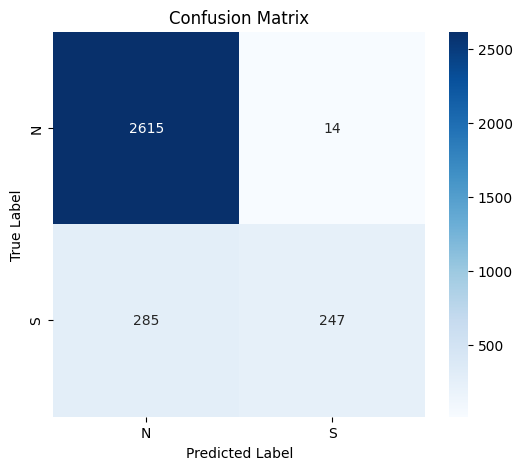

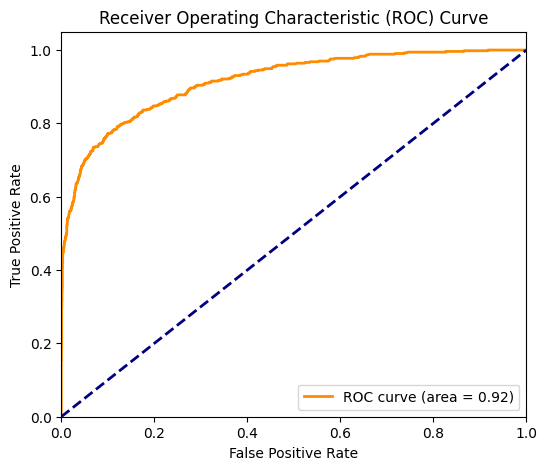

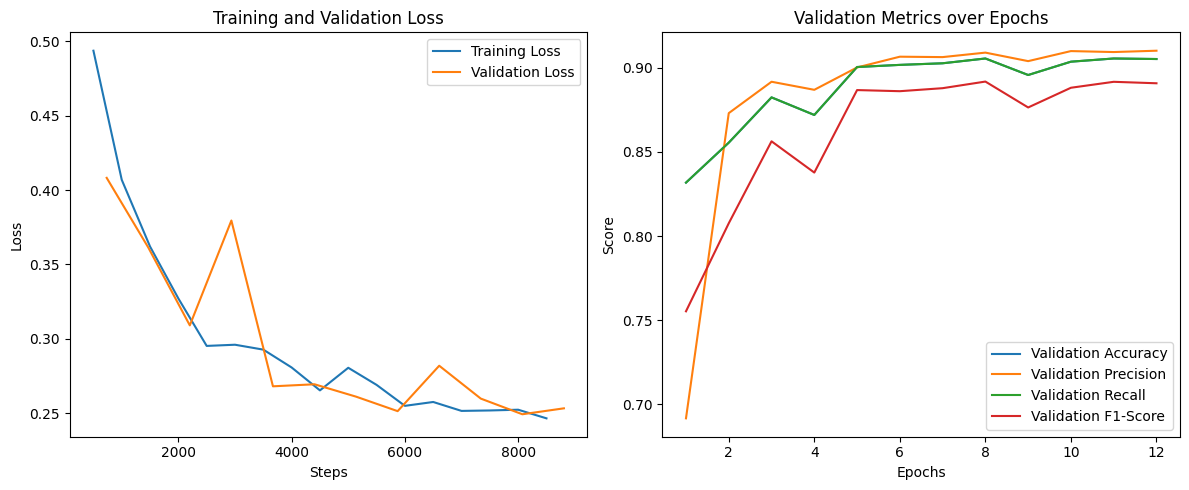


Implementation Details of Linear Projection Layer:
- A `linear_projection` layer (nn.Linear) was added after the mean pooling step in `CustomBertForSequenceClassificationWithMeanPooling`.
- It reduces the dimensionality of the pooled embeddings from `config.hidden_size` (1024 for bert-large-portuguese-cased) to `config.reduced_embedding_dim` (256).
- A GELU activation function is applied after the linear projection.
- The final classification head (`self.classifier`) then takes this 256-dimensional vector as input.
- This approach aims to reduce the number of parameters in the classification head, potentially speeding up training and reducing the risk of overfitting, especially when freezing most of the base BERT model.

Evaluation Results:
{'accuracy': 0.9054096804808605, 'precision': 0.9092364315574998, 'recall': 0.9054096804808605, 'f1': 0.8915651604448387}



In [46]:
#2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

# Get predictions on the test set
print("Getting predictions on the test set...")
predictions = trainer.predict(test_dataset)

# Extract logits and true labels
logits = predictions.predictions
y_pred_raw = np.argmax(logits, axis=-1)
y_true = predictions.label_ids

# Compute metrics using the compute_metrics function with correct arguments
metrics = compute_metrics((predictions.predictions, predictions.label_ids))
print("Evaluation Metrics:", metrics)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred_raw)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['N', 'S'], yticklabels=['N', 'S'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# ROC Curve
# Ensure y_scores are probabilities for the positive class
y_scores = logits[:, 1] # Probability of class 'S' (positive class)
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Training History Plots
# trainer.state.log_history contains training and evaluation logs
history = trainer.state.log_history

# Filter for relevant entries for training loss (should only be steps where 'loss' is present but not 'eval_loss')
train_loss_entries = [entry for entry in history if 'loss' in entry and 'eval_loss' not in entry]
train_loss = [entry['loss'] for entry in train_loss_entries]
steps = [entry['step'] for entry in train_loss_entries]

# Filter for relevant entries for evaluation metrics (should contain 'eval_loss' or other eval metrics)
eval_entries = [entry for entry in history if 'eval_loss' in entry]
eval_loss = [entry['eval_loss'] for entry in eval_entries]
eval_steps = [entry['step'] for entry in eval_entries]

# Ensure these lists are populated correctly for plotting
if eval_entries:
    eval_accuracy = [entry['eval_accuracy'] for entry in eval_entries]
    eval_precision = [entry['eval_precision'] for entry in eval_entries]
    eval_recall = [entry['eval_recall'] for entry in eval_entries]
    eval_f1 = [entry['eval_f1'] for entry in eval_entries]
    epochs = range(1, len(eval_loss) + 1) # Assuming eval_loss is recorded per epoch
else:
    print("No evaluation history found for plotting metrics.")
    eval_accuracy, eval_precision, eval_recall, eval_f1, epochs = [], [], [], [], []

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(steps, train_loss, label='Training Loss')
# Only plot validation loss if there is evaluation history
if eval_loss:
    plt.plot(eval_steps, eval_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
# Only plot validation metrics if there is evaluation history
if eval_accuracy:
    plt.plot(epochs, eval_accuracy, label='Validation Accuracy')
    plt.plot(epochs, eval_precision, label='Validation Precision')
    plt.plot(epochs, eval_recall, label='Validation Recall')
    plt.plot(epochs, eval_f1, label='Validation F1-Score')
    plt.title('Validation Metrics over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Score')
    plt.legend()
else:
    plt.text(0.5, 0.5, 'No validation metrics to display', horizontalalignment='center', verticalalignment='center', transform=plt.gca().transAxes)
    plt.title('Validation Metrics over Epochs')

plt.tight_layout()
plt.show()

# Summarize implementation of linear projection layer and evaluation results
summary = f"""
Implementation Details of Linear Projection Layer:
- A `linear_projection` layer (nn.Linear) was added after the mean pooling step in `CustomBertForSequenceClassificationWithMeanPooling`.
- It reduces the dimensionality of the pooled embeddings from `config.hidden_size` (1024 for bert-large-portuguese-cased) to `config.reduced_embedding_dim` (256).
- A GELU activation function is applied after the linear projection.
- The final classification head (`self.classifier`) then takes this 256-dimensional vector as input.
- This approach aims to reduce the number of parameters in the classification head, potentially speeding up training and reducing the risk of overfitting, especially when freezing most of the base BERT model.

Evaluation Results:
{metrics}
"""
print(summary)